In [2]:
from sklearn.datasets import load_breast_cancer
data = load_breast_cancer(as_frame=True)
df= data.frame
df.head()


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.shape

(569, 31)

In [4]:
corr=df.corr()['target'].sort_values(ascending=False)
corr

target                     1.000000
smoothness error           0.067016
mean fractal dimension     0.012838
texture error              0.008303
symmetry error             0.006522
fractal dimension error   -0.077972
concavity error           -0.253730
compactness error         -0.292999
worst fractal dimension   -0.323872
mean symmetry             -0.330499
mean smoothness           -0.358560
concave points error      -0.408042
mean texture              -0.415185
worst symmetry            -0.416294
worst smoothness          -0.421465
worst texture             -0.456903
area error                -0.548236
perimeter error           -0.556141
radius error              -0.567134
worst compactness         -0.590998
mean compactness          -0.596534
worst concavity           -0.659610
mean concavity            -0.696360
mean area                 -0.708984
mean radius               -0.730029
worst area                -0.733825
mean perimeter            -0.742636
worst radius              -0

In [5]:
df.columns

Index(['mean radius', 'mean texture', 'mean perimeter', 'mean area',
       'mean smoothness', 'mean compactness', 'mean concavity',
       'mean concave points', 'mean symmetry', 'mean fractal dimension',
       'radius error', 'texture error', 'perimeter error', 'area error',
       'smoothness error', 'compactness error', 'concavity error',
       'concave points error', 'symmetry error', 'fractal dimension error',
       'worst radius', 'worst texture', 'worst perimeter', 'worst area',
       'worst smoothness', 'worst compactness', 'worst concavity',
       'worst concave points', 'worst symmetry', 'worst fractal dimension',
       'target'],
      dtype='str')

In [6]:
x = df[["smoothness error","mean fractal dimension","texture error","symmetry error","fractal dimension error"]]
y = df["target"]

In [7]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)

In [8]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
x_train_scaler=scaler.fit_transform(x_train)
x_test_scaler=scaler.transform(x_test)

In [9]:
from sklearn.linear_model import LogisticRegression
model=LogisticRegression()
model.fit(x_train_scaler, y_train)
y_pred=model.predict(x_test_scaler)

In [10]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Precision:",precision_score(y_test,y_pred))
print("Recall:",recall_score(y_test,y_pred))
print("F1-Score:",f1_score(y_test,y_pred))

Accuracy: 0.6403508771929824
Precision: 0.6371681415929203
Recall: 1.0
F1-Score: 0.7783783783783784


In [11]:
x=df.drop(columns=["target"])
y=df["target"]

In [12]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)


In [13]:
scaler2=StandardScaler()
x_train_scaler2=scaler2.fit_transform(x_train)
x_test_scaler2=scaler2.transform(x_test)

In [14]:
model2=LogisticRegression()
model2.fit(x_train_scaler2, y_train)
y_pred2=model2.predict(x_test_scaler2)

In [15]:
print("Accuracy2:",accuracy_score(y_test,y_pred2))
print("Precision2:",precision_score(y_test,y_pred2))
print("Recall2:",recall_score(y_test,y_pred2))
print("F1-Score2:",f1_score(y_test,y_pred2))

Accuracy2: 0.9824561403508771
Precision2: 0.9861111111111112
Recall2: 0.9861111111111112
F1-Score2: 0.9861111111111112


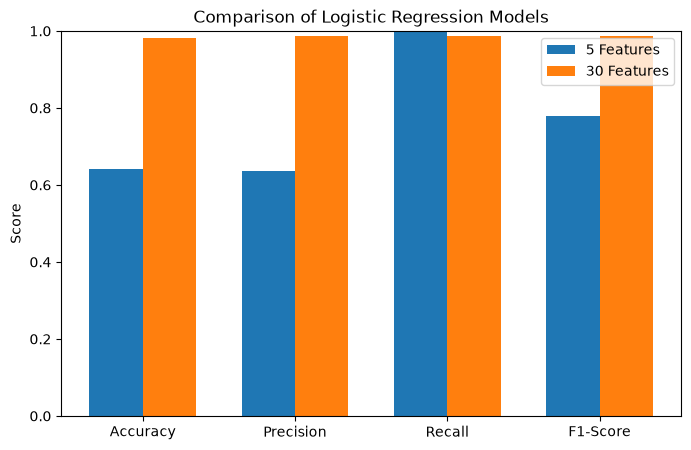

In [16]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score
metrics=["Accuracy","Precision","Recall","F1-Score"]
model_scores=[accuracy_score(y_test,y_pred),precision_score(y_test,y_pred),recall_score(y_test,y_pred),f1_score(y_test,y_pred)]
model2_scores=[accuracy_score(y_test,y_pred2),precision_score(y_test,y_pred2),recall_score(y_test,y_pred2),f1_score(y_test,y_pred2)]
x=np.arange(len(metrics))
width=0.35
plt.figure(figsize=(8,5))
plt.bar(x-width/2,model_scores,width,label="5 Features")
plt.bar(x+width/2,model2_scores,width,label="30 Features")
plt.xticks(x, metrics)
plt.ylabel("Score")
plt.ylim(0,1)
plt.title("Comparison of Logistic Regression Models")
plt.legend()
plt.show()


In [17]:
x=df.drop(columns=["target"])
y=df["target"]

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)
scaler3=StandardScaler()
x_train_scaler3=scaler3.fit_transform(x_train)
x_test_scaler3=scaler3.transform(x_test)
model3=LogisticRegression()
model3.fit(x_train_scaler3, y_train)
y_pred3=model3.predict(x_test_scaler3)

In [19]:
model3.classes_

array([0, 1])

In [20]:
# تمرین دوم
probamalignant=model3.predict_proba(x_test_scaler3)
malignant_proba=probamalignant[:,0]
print(malignant_proba.shape)

(114,)


In [21]:
import numpy as np
threshold=0.5
y_pred_threshold=np.where(malignant_proba >= threshold, 0, 1)
y_pred_threshold

array([0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1,
       1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 1])

In [22]:

print(y_test.shape)
print(y_pred_threshold.shape)
print(y_test[:5])
print(y_pred_threshold[:5])

(114,)
(114,)
256    0
428    1
501    0
363    1
564    0
Name: target, dtype: int64
[0 1 0 1 0]


In [23]:

precision=precision_score(y_test,y_pred_threshold,pos_label=0)
recall=recall_score(y_test,y_pred_threshold,pos_label=0)
print("Precision:",precision)
print("Recall:",recall)

Precision: 0.9761904761904762
Recall: 0.9761904761904762


In [27]:
thresholds=np.arange(0.05,1.0,0.05)
print(threshold)
print(type(threshold))

[0.05 0.1  0.15 0.2  0.25 0.3  0.35 0.4  0.45 0.5  0.55 0.6  0.65 0.7
 0.75 0.8  0.85 0.9  0.95]
<class 'numpy.ndarray'>


In [28]:
precisions = []
recalls = []

for threshold in thresholds:
    y_pred_threshold = np.where(malignant_proba >= threshold, 0, 1)

    p = precision_score(y_test, y_pred_threshold, pos_label=0)
    r = recall_score(y_test, y_pred_threshold, pos_label=0)

    precisions.append(p)
    recalls.append(r)

In [29]:
valid = np.array(precisions) > 0.90
best_index = np.argmax(np.array(recalls)[valid])

In [30]:
valid_indices = np.where(valid)[0]
best_index = valid_indices[np.argmax(np.array(recalls)[valid])]

In [31]:
best_threshold = thresholds[best_index]
best_precision = precisions[best_index]
best_recall = recalls[best_index]

print(best_threshold)
print(best_precision)
print(best_recall)

0.4
0.9111111111111111
0.9761904761904762


In [32]:
x = df.drop(columns=["target"])
y = df["target"]

In [33]:
x_train, x_test, y_train, y_test = train_test_split(x,y,test_size=0.2, random_state=42, stratify=y)
scaler4=StandardScaler()
x_train_scaler4=scaler4.fit_transform(x_train)
x_test_scaler4=scaler4.transform(x_test)

In [34]:
from sklearn.neighbors import KNeighborsClassifier
knn=KNeighborsClassifier(n_neighbors=5)
knn.fit(x_train_scaler4, y_train)
y_pred_knn=knn.predict(x_test_scaler4)

In [35]:
print("Accuracy:",accuracy_score(y_test,y_pred_knn))

Accuracy: 0.956140350877193


In [36]:
k_values = range(1, 16)
cv_scores = []

In [37]:
from sklearn.model_selection import cross_val_score
for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k,metric="manhattan")
    scores = cross_val_score(knn, x_train_scaler4, y_train, cv=5, scoring='accuracy')
    cv_scores.append(scores.mean())

In [40]:
max(cv_scores)

np.float64(0.9714285714285715)

In [42]:
best_k = k_values[cv_scores.index(max(cv_scores))]
best_k

4

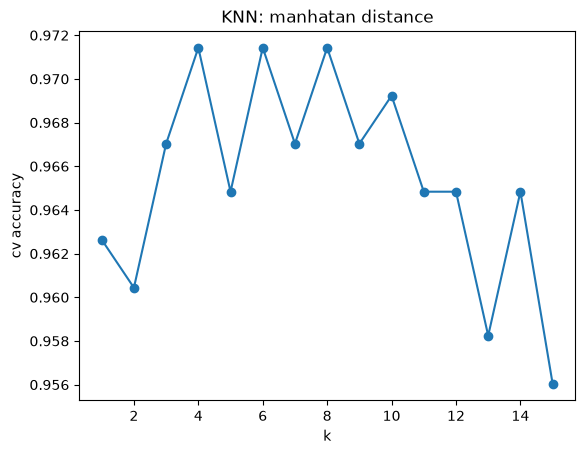

In [43]:
import matplotlib.pyplot as plt

plt.plot(k_values, cv_scores,marker='o')
plt.xlabel('k')
plt.ylabel('cv accuracy')
plt.title('KNN: manhatan distance')
plt.show()

In [44]:
from sklearn.tree import DecisionTreeClassifier
depths=[2,3,4,5,6,7,8,9,10,None]
cv_scores2=[]
for depth in depths:
    tree = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(tree, x_train_scaler4, y_train, cv=5)
    cv_scores2.append(scores.mean())

In [45]:
max(cv_scores2)

np.float64(0.9384615384615385)

In [47]:
best_depth = depths[cv_scores2.index(max(cv_scores2))]
best_depth

4

In [48]:
best_tree=DecisionTreeClassifier(max_depth=best_depth, random_state=42)
best_tree.fit(x_train_scaler4, y_train)
y_pred_tree=best_tree.predict(x_test_scaler4)

In [49]:
accuracy_score(y_test,y_pred_tree)

0.9385964912280702